---
title: "Figures: The Ramsey/Cass-Koopmans (RCK) Model with Government"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

<!-- Generated from RCKWithGov_SST.ipynb by code/notebook_math.py. Don't edit this notebook: edit RCKWithGov_SST.ipynb, where the math is written with the book's macros, and run the script. -->
Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=RCKWithGov.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/growth/RCKWithGov/RCKWithGov.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/growth/RCKWithGov/RCKWithGov.ipynb).

In [the RCK model with government](https://intertemporal-choice.github.io/content/growth/rckwithgov), there is no population or productivity growth, so capital $k$ and consumption $c$ are per person. Output is $k^{\alpha}$, capital depreciates at the rate $\delta$, the government spends $X$ per person, paid for by lump-sum taxes, and households have CRRA utility with relative risk aversion $\varrho$ and time preference rate $\vartheta$. Capital and consumption move according to

$$
\dot{k} = k^{\alpha} - \delta k - c - X, \qquad \frac{\dot{c}}{c} = \varrho^{-1}\left(\alpha k^{\alpha-1} - \delta - \vartheta\right),
$$

and the interest rate is $\mathsf{r} = \alpha k^{\alpha-1} - \delta$. Spending shifts the $\dot{k}=0$ locus down and leaves the $\dot{c}=0$ locus, at $\bar{k}$, where it was. The notebook draws what happens when spending rises unexpectedly, for good or for ten years.

In [ ]:
# Run anywhere: install the book's package (it brings numpy, scipy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    import importlib.util, sys
    if importlib.util.find_spec("pip"):
        %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io
    else:  # a Python without pip, as uv makes: install with uv, or say what to do
        !uv pip install -q --python {sys.executable} git+https://github.com/intertemporal-choice/intertemporal-choice.github.io || echo "Neither pip nor uv can install the book's package here: choose a kernel whose Python has pip, or the course's own environment."

In [ ]:
from dataclasses import dataclass, replace

import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import brentq

In [ ]:
import matplotlib.pyplot as plt

from intertemporal_choice import fiscal, style

style.use_book_style()

## The economy

`Economy` holds the parameters of the RCK chapter's figures, without growth: $\varrho = 2$, $\alpha = 0.3$, $\vartheta = 0.02$ and $\delta = 0.08$. Spending $X$ is 20 percent of steady-state output, and the experiments raise it by 5 percent of output. Since $\bar{k}$ does not depend on spending, neither does steady-state output.

In [ ]:
@dataclass(frozen=True)
class Economy:
    rho: float = 2.0     # relative risk aversion
    alpha: float = 0.3   # capital's share of output
    theta: float = 0.02  # time preference rate
    delta: float = 0.08  # depreciation rate
    X: float = 0.0       # government spending per person, paid for by lump-sum taxes


def output(e, k):
    return k**e.alpha


def interest(e, k):  # the marginal product of capital, net of depreciation
    return e.alpha * k ** (e.alpha - 1) - e.delta


def kdot(e, k, c):
    return output(e, k) - e.delta * k - c - e.X


def cdot(e, k, c):
    return c * (interest(e, k) - e.theta) / e.rho


def steady_state(e):
    k = (e.alpha / (e.theta + e.delta)) ** (1 / (1 - e.alpha))  # the modified golden rule: r = theta
    return k, output(e, k) - e.delta * k - e.X


def kdot_zero(e, k):  # consumption on the kdot = 0 locus
    return output(e, k) - e.delta * k - e.X

## The saddle path, by time elimination

Along any path, $dc/dk = \dot{c}/\dot{k}$, a differential equation in $k$ alone. At the steady state both $\dot{c}$ and $\dot{k}$ are zero, so the equation is solved twice, outward from the steady state on each side, starting a small step away along the saddle path's slope there: the direction of the eigenvector with the negative eigenvalue of the system linearized at the steady state.

In [ ]:
def saddle_slope(e):
    """dc/dk along the saddle path at the steady state."""
    k, c = steady_state(e)
    jacobian = np.array([
        [interest(e, k), -1.0],                                           # d kdot/dk, d kdot/dc
        [c * e.alpha * (e.alpha - 1) * k ** (e.alpha - 2) / e.rho, 0.0],  # d cdot/dk, d cdot/dc
    ])
    values, vectors = np.linalg.eig(jacobian)
    stable = vectors[:, np.argmin(values)]
    return stable[1] / stable[0]


def saddle_path(e, k_low, k_high):
    """The saddle path's consumption as a function of k on [k_low, k_high]."""
    k_ss, c_ss = steady_state(e)
    slope = saddle_slope(e)
    step = 1e-5 * k_ss
    pieces = []
    for end, side in ((k_low, -1), (k_high, 1)):
        start = k_ss + side * step
        solution = solve_ivp(lambda k, c: cdot(e, k, c) / kdot(e, k, c), (start, end), [c_ss + side * step * slope],
                             rtol=1e-10, atol=1e-12, max_step=0.01)
        pieces.append((solution.t, solution.y[0]))
    (k_left, c_left), (k_right, c_right) = pieces
    return interp1d(np.concatenate([k_left[::-1], [k_ss], k_right]), np.concatenate([c_left[::-1], [c_ss], c_right]),
                    kind="cubic")

## A temporary increase

Spending rises at date 0 and returns to its old level at date $t_{1}$, as everyone knows. From $t_{1}$ on the economy must be on the original saddle path, and consumption cannot jump at $t_{1}$, a date everyone foresaw. So `temporary` searches between the two steady states' consumption for the consumption at date 0 from which the equations of motion with high spending reach the original saddle path exactly at $t_{1}$. After $t_{1}$ the economy rides the original saddle path back to its steady state.

In [ ]:
def follow(e, k0, c0, t1, k_floor=0.0):
    """The (k, c) path from (k0, c0) under economy e until date t1, or until k falls to k_floor."""
    def exhausted(t, y):
        return y[0] - k_floor
    exhausted.terminal = True
    return solve_ivp(lambda t, y: [kdot(e, *y), cdot(e, *y)], (0, t1), [k0, c0], events=exhausted,
                     rtol=1e-10, atol=1e-12, dense_output=True, max_step=0.05)


def temporary(e_low, e_high, t1):
    """Consumption at date 0, the path while spending is high, and the original saddle path."""
    k_ss, c_ss = steady_state(e_low)
    saddle = saddle_path(e_low, 0.05 * k_ss, 1.5 * k_ss)

    def miss(c0):
        path = follow(e_high, k_ss, c0, t1, k_floor=0.05 * k_ss)
        if path.status == 1:  # capital ran out before t1: consumption started too high
            return 1.0
        k1, c1 = path.y[:, -1]
        return c1 - saddle(k1)

    c0 = brentq(miss, steady_state(e_high)[1] + 1e-9, c_ss - 1e-9, xtol=1e-12)
    return c0, follow(e_high, k_ss, c0, t1), saddle


def back(e, saddle, k1, duration):
    """Capital along the saddle path, from k1, for `duration` years."""
    return solve_ivp(lambda t, k: [kdot(e, k[0], saddle(k[0]))], (0, duration), [k1], rtol=1e-10, atol=1e-12,
                     dense_output=True, max_step=0.1)

## The phase diagram

A permanent increase lowers consumption at once by the increase, from E to E′, and nothing else moves: capital is already at $\bar{k}$, and the new steady state is the only point of the new saddle path there. A temporary increase lowers consumption by less, to A. Capital then runs down while spending is high, until it reaches the original saddle path at B, at $t_{1}$, and the economy returns along it to E.

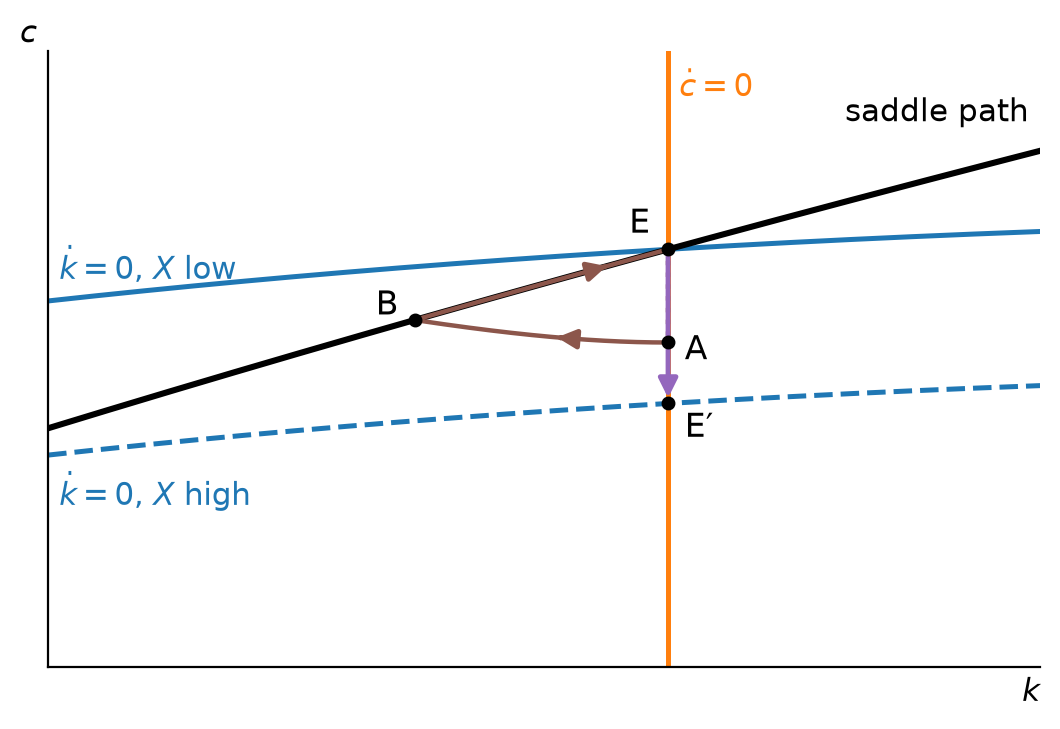

In [ ]:
e = Economy()
k_ss, _ = steady_state(e)
e = replace(e, X=0.2 * output(e, k_ss))
high = replace(e, X=e.X + 0.05 * output(e, k_ss))
t1 = 10.0
c0, during, saddle = temporary(e, high, t1)
k1, c1 = during.y[:, -1]
returning = back(e, saddle, k1, 60.0)

k = np.linspace(0.80 * k_ss, 1.12 * k_ss, 300)
k_during, c_during = during.sol(np.linspace(0, t1, 200))
k_back = returning.sol(np.linspace(0, 60.0, 400))[0]
fig, ax = plt.subplots()
fiscal.draw_phase(ax, k, kdot_zero(e, k), kdot_zero(high, k), (k_ss, steady_state(e)[1], steady_state(high)[1]),
                  (k, saddle(k)), (k_during, c_during), (k_back, saddle(k_back)), (0.68, 1.0))
style.save(fig, "RCKGovPhase")

## Over time

The temporary increase raises the interest rate $\mathsf{r}$, most when the spending ends, and capital falls while it lasts; the permanent one leaves both where they were.

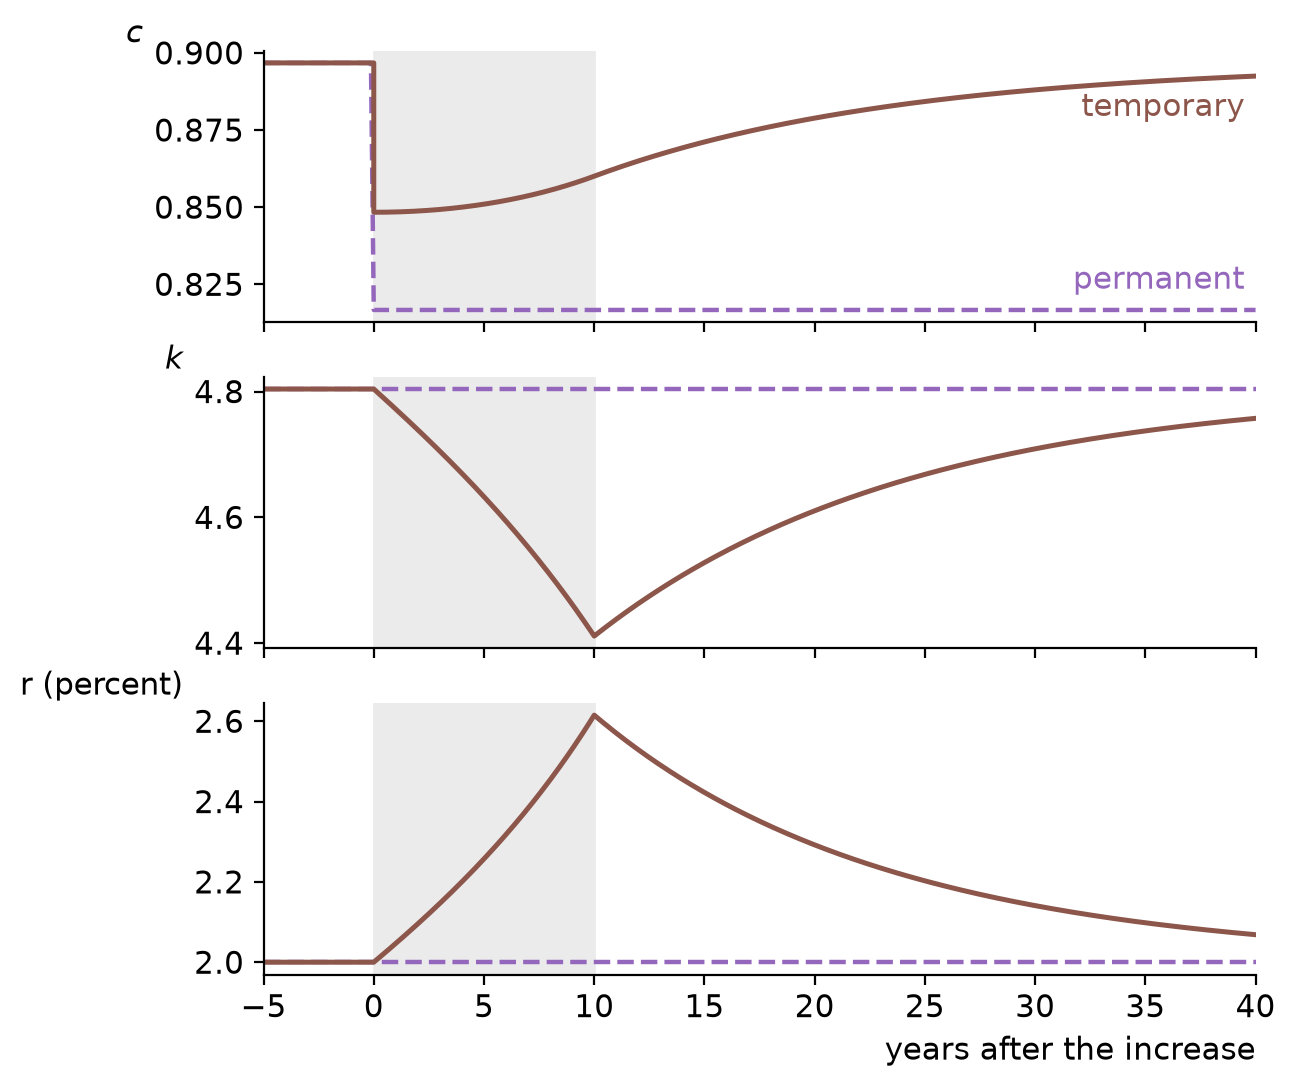

In [ ]:
before, after = np.linspace(-5, 0, 40), np.linspace(t1, 40, 300)
t = np.concatenate([before, np.linspace(0, t1, 200), after])
k_path = np.concatenate([np.full_like(before, k_ss), during.sol(np.linspace(0, t1, 200))[0], returning.sol(after - t1)[0]])
c_path = np.concatenate([np.full_like(before, steady_state(e)[1]), during.sol(np.linspace(0, t1, 200))[1],
                         saddle(returning.sol(after - t1)[0])])
c_permanent = np.where(t < 0, steady_state(e)[1], steady_state(high)[1])
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(6.4, 6.0))
fiscal.draw_paths(axes, t, {"c": c_path, "k": k_path, "r": 100 * interest(e, k_path)},
                  {"c": c_permanent, "k": np.full_like(t, k_ss), "r": np.full_like(t, 100 * e.theta)}, t1)
style.save(fig, "RCKGovPaths")

## Checks

The numbers the chapter quotes, and the properties of the paths it describes.

In [ ]:
dX = high.X - e.X
assert round(k_ss, 3) == 4.804 and np.isclose(e.X / output(e, k_ss), 0.2) and np.isclose(dX / output(e, k_ss), 0.05)
# A permanent increase lowers steady-state consumption by exactly the increase; capital and r do not move.
assert np.isclose(steady_state(e)[1] - steady_state(high)[1], dX) and np.isclose(interest(e, k_ss), e.theta)
# A temporary one lowers consumption at once by about three fifths of the increase.
share = (steady_state(e)[1] - c0) / dX
assert 0.59 < share < 0.62, share
# Capital falls by about 8 percent by the time the spending ends, and r rises from 2 to about 2.6 percent.
assert 0.91 < k1 / k_ss < 0.93 and 2.55 < 100 * interest(e, k1) < 2.7
# On the original saddle path at t1, with no jump in consumption there.
assert abs(c1 - saddle(k1)) < 1e-7
# Capital falls throughout the episode, and consumption rises from date 0 on.
k_d, c_d = during.sol(np.linspace(0, t1, 200))
assert np.all(np.diff(k_d) < 0) and np.all(np.diff(c_d) > 0) and np.all(np.diff(saddle(k_back)) > 0)
print(f"consumption falls by {share:.3f} of the increase; k(t1)/k_ss = {k1 / k_ss:.3f}; r(t1) = {100 * interest(e, k1):.2f} percent")

consumption falls by 0.605 of the increase; k(t1)/k_ss = 0.918; r(t1) = 2.62 percent
